# Unbalanced Gaussian bump

Repeat the Gaussian-bump comparison with population growth. The data and frozen map are
identical to the balanced tutorial. The terminal population mass is explicitly set to twice
the initial mass. Compare beta = 1 and beta = 0.1, with and without synchronization, and
show instantaneous growth along every learned trajectory.

In [1]:
from pathlib import Path
import sys
import uuid

example_dir = next(parent / "examples" for parent in (Path.cwd(), *Path.cwd().parents)
                   if (parent / "examples" / "synthetic_gaussian_assets.py").is_file())
if str(example_dir) not in sys.path:
    sys.path.insert(0, str(example_dir))

import anndata as ad
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import coati as ct
from gaussian_map import evaluate_bump_map, plot_map_performance
from gaussian_comparison import (
    make_shared_initial_checkpoint,
    plot_gaussian_sync,
    plot_bump_height,
    compare_gaussian_runs,
)
from synthetic_gaussian_assets import load_shared_gaussian_assets, resolve_asset_directory

%matplotlib inline
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
run_dir = Path("outputs") / ("gaussian-bump-" + uuid.uuid4().hex[:8])
run_dir.mkdir(parents=True)
print("Result directory:", run_dir)

from synthetic_gaussian_assets import plot_growth_along_trajectories

Result directory: outputs/gaussian-bump-89dd1efe


## Shared data and map

The observed snapshots contain 1,000 initial and 2,000 terminal cells. Reusing the same
assets isolates the effect of unbalanced training rather than changing the geometry.

In [2]:
asset_dir = resolve_asset_directory()
cells, T, map_payload = load_shared_gaussian_assets(directory=asset_dir)
map_pairs = ad.read_h5ad(asset_dir / "map_pairs.h5ad")
data = ct.TemporalData.from_anndata(
    cells, obsm_key="X_latent", secondary_obsm_key="X_secondary"
)

summary = cells.obs.groupby(["time", "celltype"], observed=True).size().rename("Cells").to_frame()
assert [len(snapshot) for snapshot in data.primary] == [1000, 2000]
assert not any(parameter.requires_grad for parameter in T.parameters())
summary

Cells
time celltype         
0.0  Initial      1000
1.0  Terminal A   1000
     Terminal B   1000

## Inspect the frozen map

,Pairs,XY_RMSE,Z_RMSE,Z_MAE
Evaluation,,,,
Held-out observed,434,0.000047,0.021079,0.004067
Held-out support,1066,0.000065,0.005544,0.003500
Independent grid,9216,0.000067,0.005036,0.002998


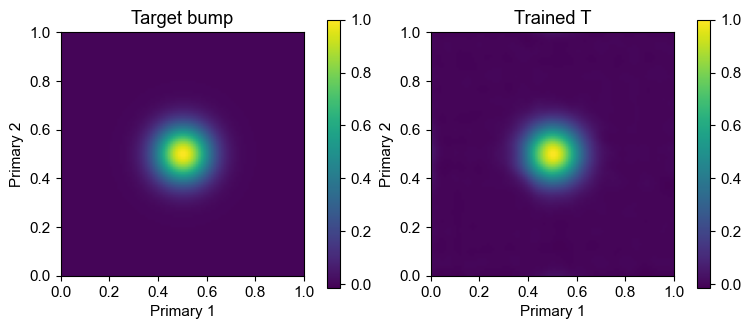

Best validation step: 1500
Grid z correlation: 0.999378
Learned height at (0.5, 0.5): 0.999919


In [3]:
map_scores, map_grid = evaluate_bump_map(T, map_pairs, grid_n=96)
display(map_scores.round(6))
plot_map_performance(map_grid)
plt.show()
print(f"Best validation step: {map_payload['fit']['best_step']}")
print(f"Grid z correlation: {map_grid['z_correlation']:.6f}")
print(f"Learned height at (0.5, 0.5): {map_grid['center_predicted_height']:.6f}")

## Configure unbalanced transport

`balanced=False` enables the growth field and mass-matching loss. `biological_num=[1, 2]`
is the relative population-mass prior, so the target terminal mass is 2. The observed sample
counts imply the same ratio, but writing the prior explicitly makes the intended experiment
independent of future resampling. `mass_weight=100` and `global_mass=True` enforce both local
allocation and total population mass. In the implementation, beta is `growth_weight`, the
`alpha_growth` coefficient multiplying the learned growth rate and growth action.

In [4]:
base_config = ct.Config(
    multimodal=True,
    balanced=False,
    iterations=3000,
    batch_size=256,
    hidden_dim=256,
    secondary_weight=.5,
    growth_weight=1.,
    mass_weight=100.,
    global_mass=True,
    extra={
        "biological_num": [1.0, 2.0],
        "median_n_sample": 512,
        "floor_n_sample": 256,
        "adaptive_lambda": True,
    },
)
configs = {}
for beta in [1.0, .1]:
    beta_config = base_config.with_parameters(growth_weight=beta)
    configs[f"beta={beta:g} | Without sync"] = beta_config.with_parameters(
        multimodal=False, secondary_weight=0.
    )
    configs[f"beta={beta:g} | With sync"] = beta_config

pd.DataFrame({name: {key: cfg.to_dict()[key] for key in
    ["niters", "num_samples", "sync_loss", "sync_weight", "unbalancedModel",
     "alpha_growth", "mass_loss", "mass_coefficient", "global_mass", "biological_num"]}
    for name, cfg in configs.items()})

,beta=1 | Without sync,beta=1 | With sync,beta=0.1 | Without sync,beta=0.1 | With sync
niters,3000,3000,3000,3000
num_samples,256,256,256,256
sync_loss,False,True,False,True
sync_weight,0.0,0.5,0.0,0.5
unbalancedModel,True,True,True,True
alpha_growth,1.0,1.0,0.1,0.1
mass_loss,True,True,True,True
mass_coefficient,100.0,100.0,100.0,100.0
global_mass,True,True,True,True
biological_num,"[1.0, 2.0]","[1.0, 2.0]","[1.0, 2.0]","[1.0, 2.0]"


## Train the vector and growth fields

All four runs start from identical unbalanced network weights. Each model contains a
velocity field and an instantaneous log-growth field; only beta and synchronization differ.

In [5]:
initial = make_shared_initial_checkpoint(base_config, run_dir / "initial.pt")
results = {}
for name, cfg in configs.items():
    print("Training:", name, flush=True)
    slug = name.lower().replace(" | ", "-").replace("=", "").replace(".", "p").replace(" ", "-")
    results[name] = ct.train_vector_field(
        cells, cfg, use_rep="X_latent", secondary_obsm_key="X_secondary",
        T_model=T if cfg.multimodal else None,
        output_dir=run_dir / slug,
        warm_start_path=initial,
    )

Training: beta=1 | Without sync


Training: beta=1 | With sync


Training: beta=0.1 | Without sync


Training: beta=0.1 | With sync


## Learned trajectories

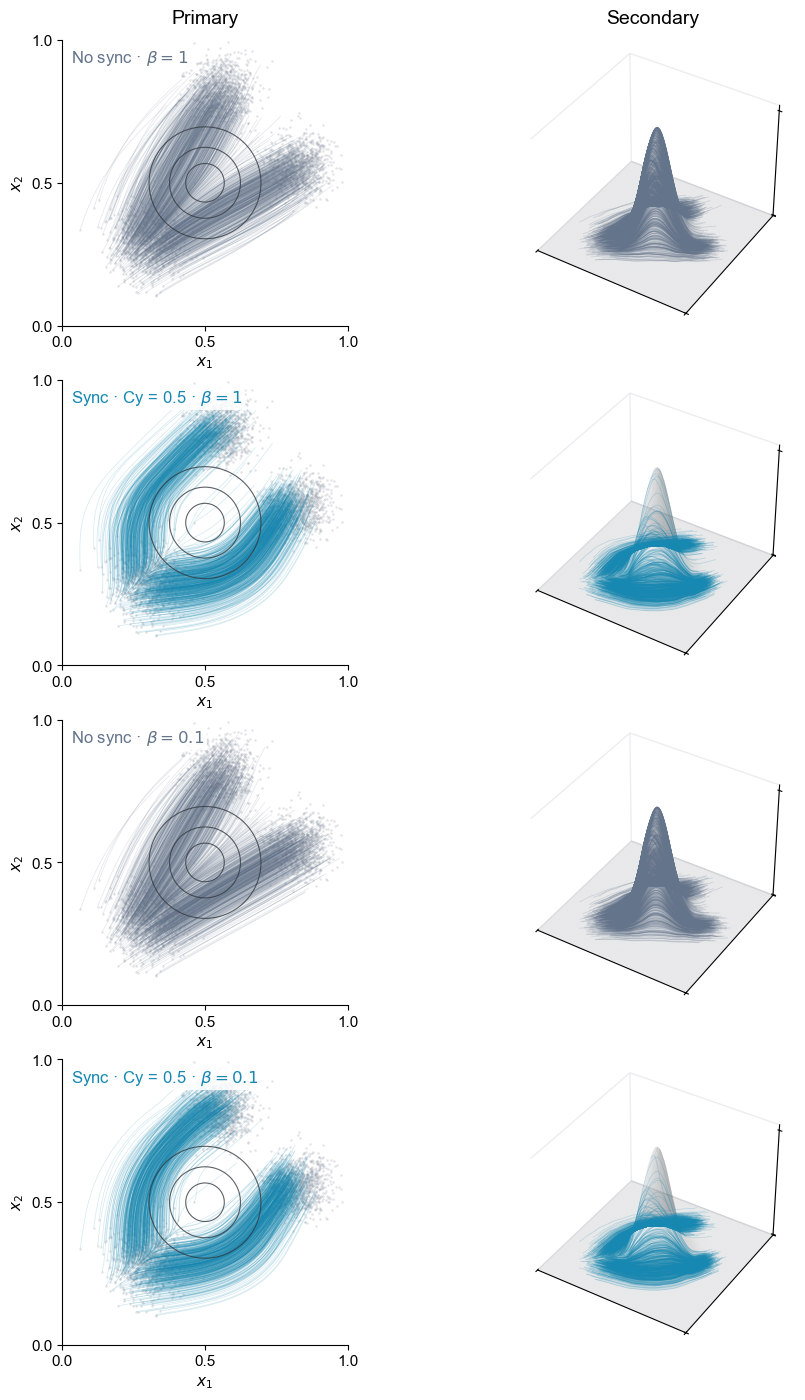

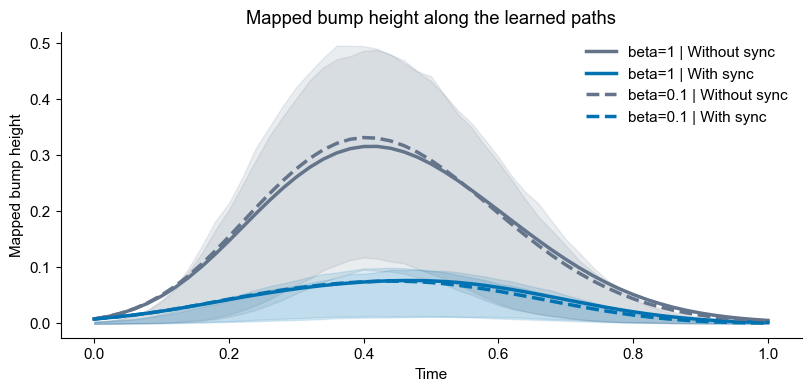

In [6]:
predictions = {}
for name, result in results.items():
    prediction = result.predict_trajectory(times=np.linspace(0., 1., 51), method="rk4")
    with torch.no_grad():
        prediction["secondary"] = T(torch.as_tensor(prediction["primary"], dtype=torch.float32)).numpy()
    predictions[name] = prediction

plot_gaussian_sync(data, T, results, predictions)
plt.show()
plot_bump_height(predictions)
plt.show()

## Growth along trajectories

Blue segments indicate negative instantaneous growth and red segments indicate positive
instantaneous growth. The colour is the fitted $d\log w/dt$ evaluated along each path;
the title reports the integrated terminal mass against the target of 2. Because both terminal
populations expand in this example, the learned raw growth may remain positive and therefore
use mainly the red half of the diverging scale.

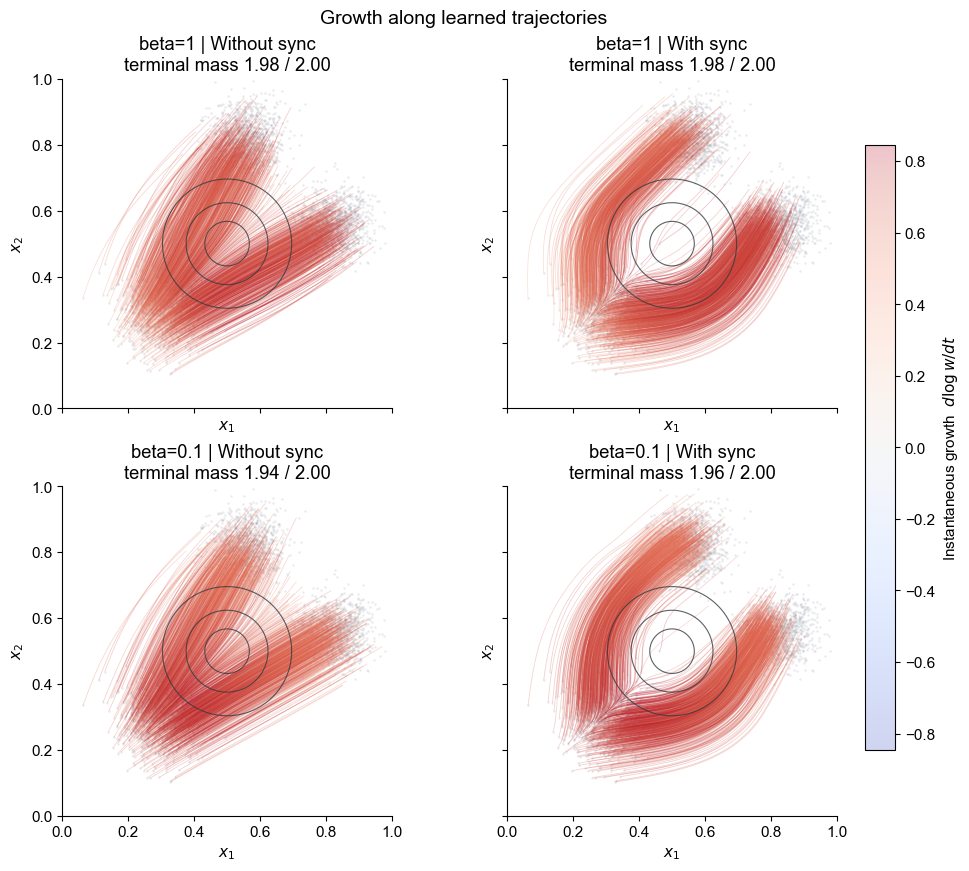

In [7]:
growth_figure, growth = plot_growth_along_trajectories(data, results, predictions)
plt.show()

## Mass and transport diagnostics

In [8]:
scores = compare_gaussian_runs(results, predictions)
display(scores.T.round(6))
pd.DataFrame({name: result.evaluate() for name, result in results.items()}).T.round(6)

Model,beta=1 | Without sync,beta=1 | With sync,beta=0.1 | Without sync,beta=0.1 | With sync
Primary endpoint Sinkhorn,0.000653,0.001105,0.000491,0.000484
Primary kinetic energy,0.200886,0.241582,0.209753,0.260358
Secondary kinetic energy,1.372201,0.322865,1.362476,0.328599
Predicted terminal mass,1.980399,1.981807,1.940608,1.962171
Target terminal mass,2.000000,2.000000,2.000000,2.000000
Median maximum bump height,0.380701,0.043216,0.380506,0.045225
States outside unit square,0.000000,0.000000,0.000000,0.000000


,endpoint_sinkhorn_before,endpoint_sinkhorn_after,kinetic_energy_mean,endpoint_sampling_floor,predicted_mass_ratio,observed_count_ratio,secondary_endpoint_sinkhorn
beta=1 | Without sync,0.165117,0.000780,0.000201,0.000348,1.980400,2.0,NaN
beta=1 | With sync,0.165117,0.000917,0.000242,0.000348,1.981807,2.0,0.000928
beta=0.1 | Without sync,0.165117,0.000521,0.000210,0.000348,1.940608,2.0,NaN
beta=0.1 | With sync,0.165117,0.000482,0.000260,0.000348,1.962171,2.0,0.000488
